5-Fold YOLOv8n Cross-Validation for Ganoderma Detection

This notebook rebuilds the experiment from the beginning and keeps the **original `test/` split untouched** until the final independent evaluation.

### What this notebook does
1. Mounts Google Drive and expects the dataset under `MyDrive/ganoderma/`.
2. Audits images/labels and checks exact/perceptual duplicates.
3. Uses **only original `train/` + `valid/` (or `val/`) images** for 5-fold cross-validation.
4. Creates each fold **before** synthetic generation.
5. Generates fold-specific synthetic images using **only that fold's original training partition**.
6. Verifies synthetic provenance so no validation/test image can be a patch source or background.
7. Trains **all 5 folds automatically**.
8. Evaluates only each model's true held-out fold and reports mAP@50, mAP@50:95, precision, recall, and F1.
9. Optionally runs a baseline (no synthetic data) for comparison.
10. Trains one final model after CV and evaluates it once on the untouched original `test/` split.
11. Saves splits, synthetic data, provenance, models, training logs, evaluation plots, CSVs, and summaries inside `MyDrive/ganoderma/experiments/...`.

> **Important:** Do not use the old 5×5 off-diagonal cross-evaluation matrix as a validation result. Only each model's own held-out fold is a valid CV test fold.

In [1]:
# ============================================================
# 0. INSTALL DEPENDENCIES
# ============================================================
# Pinned to the Ultralytics version used in your previous notebook
# so metric behavior stays comparable.

!pip -q install "ultralytics==8.4.173" "scikit-learn>=1.4" "ImageHash>=4.3" pyyaml tqdm

In [8]:
# ============================================================
# 1. MOUNT DRIVE + CONFIGURATION
# ============================================================
from google.colab import drive
drive.mount("/content/drive")

from pathlib import Path

# ------------------------------
# Dataset location
# ------------------------------
DATASET_ROOT = Path("/content/drive/MyDrive/ganoderma")

# Your folder may be named "valid" or "val". The notebook detects it.
if (DATASET_ROOT / "valid").exists():
    VAL_FOLDER_NAME = "valid"
elif (DATASET_ROOT / "val").exists():
    VAL_FOLDER_NAME = "val"
else:
    raise FileNotFoundError(
        f"Could not find {DATASET_ROOT/'valid'} or {DATASET_ROOT/'val'}"
    )

# ------------------------------
# Experiment output location
# Everything persistent is stored under ganoderma/
# ------------------------------
EXP_NAME = "leak_free_yolov8s_cv_v1"
EXP_ROOT = DATASET_ROOT / "experiments" / EXP_NAME
EXP_ROOT.mkdir(parents=True, exist_ok=True)

# Local Colab workspace (fast temporary storage)
LOCAL_DATASET = Path("/content/ganoderma_source")
LOCAL_WORK = Path("/content/ganoderma_cv_work")

# ------------------------------
# Reproducibility
# ------------------------------
SEED = 42
N_FOLDS = 5

# ------------------------------
# Model / training
# ------------------------------
MODEL_WEIGHTS = "yolov8s.pt"
EPOCHS = 50
IMGSZ = 640
BATCH_SIZE = 30
DEVICE = 0          # GPU 0
PATIENCE = 20
WORKERS = 2

# ------------------------------
# Synthetic data
# ------------------------------
NUM_SYNTH_PER_FOLD = 500
SYNTH_MIN_PATCHES = 1
SYNTH_MAX_PATCHES = 2

# ------------------------------
# Experiment switches
# ------------------------------
RUN_SYNTH_CV = False

# Set True only if you want a direct 5-fold baseline-vs-synthetic comparison.
# True = 10 trainings total (5 baseline + 5 synth).
RUN_BASELINE_CV = False

# Skip a fold/mode when best.pt + metrics.csv already exist on Drive.
RESUME_COMPLETED = False

# Rebuild split manifests even if they already exist.
FORCE_REBUILD_SPLITS = False

# Regenerate synthetic images even if a fold already has them on Drive.
FORCE_REGENERATE_SYNTH = False

# Retrain even if a completed model/metrics already exist.
FORCE_RETRAIN = True

# Keep local fold workdirs after training. False saves Colab disk space.
KEEP_LOCAL_FOLD_WORKDIRS = False

# Final independent model:
# CV is for estimating generalization. The final model is trained separately
# and evaluated once on the untouched original test split.
RUN_FINAL_MODEL = True
NUM_SYNTH_FINAL = 500

# Optional QNN/ONNX preparation after final training.
EXPORT_FINAL_ONNX = True

# Dataset audit behavior:
STRICT_EXACT_TEST_LEAKAGE = True
PHASH_WARN_DISTANCE = 4

# ------------------------------
# Quick smoke test
# ------------------------------
# Set True to verify the full pipeline cheaply before the real run.
# It uses 1 epoch, 20 synthetic images/fold, and only Fold 1.
SMOKE_TEST = False

if SMOKE_TEST:
    EPOCHS = 1
    NUM_SYNTH_PER_FOLD = 20
    NUM_SYNTH_FINAL = 20
    FOLDS_TO_RUN = [1]
else:
    FOLDS_TO_RUN = list(range(1, N_FOLDS + 1))

print("Dataset root :", DATASET_ROOT)
print("Validation   :", VAL_FOLDER_NAME)
print("Experiment   :", EXP_ROOT)
print("Folds        :", FOLDS_TO_RUN)
print("Epochs       :", EPOCHS)
print("Synth/fold   :", NUM_SYNTH_PER_FOLD)
print("Baseline CV  :", RUN_BASELINE_CV)
print("Synthetic CV :", RUN_SYNTH_CV)
print("Final model  :", RUN_FINAL_MODEL)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Dataset root : /content/drive/MyDrive/ganoderma
Validation   : valid
Experiment   : /content/drive/MyDrive/ganoderma/experiments/leak_free_yolov8n_cv_v1
Folds        : [1, 2, 3, 4, 5]
Epochs       : 50
Synth/fold   : 500
Baseline CV  : False
Synthetic CV : False
Final model  : True


In [3]:
# ============================================================
# 2. IMPORTS, SEEDS, METRIC HELPERS
# ============================================================
import os
import gc
import cv2
import json
import math
import time
import shutil
import random
import hashlib
import warnings
import subprocess
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import imagehash
from tqdm.auto import tqdm

import torch
import ultralytics
from ultralytics import YOLO

from sklearn.model_selection import StratifiedGroupKFold

warnings.filterwarnings("ignore", category=UserWarning)

def seed_everything(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

seed_everything(SEED)

if DEVICE == 0 and not torch.cuda.is_available():
    raise RuntimeError(
        "GPU is not available. In Colab choose Runtime > Change runtime type > GPU, "
        "then reconnect your VS Code Colab session."
    )

print("Ultralytics:", ultralytics.__version__)
print("PyTorch    :", torch.__version__)
print("CUDA       :", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU        :", torch.cuda.get_device_name(0))

def metric_value(res, name):
    """Version-tolerant accessor for Ultralytics detection metrics."""
    v = getattr(res.box, name)
    if callable(v):
        v = v()
    return float(v)

def extract_metrics(res):
    p = metric_value(res, "mp")
    r = metric_value(res, "mr")
    map50 = metric_value(res, "map50")
    map5095 = metric_value(res, "map")
    f1 = 2 * p * r / (p + r + 1e-12)
    return {
        "mAP50": map50,
        "mAP50-95": map5095,
        "Precision": p,
        "Recall": r,
        "F1": f1,
    }

def write_json(obj, path):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    with open(path, "w") as f:
        json.dump(obj, f, indent=2, default=str)

def sync_tree(src, dst):
    """Replace dst with a copy of src."""
    src, dst = Path(src), Path(dst)
    if dst.exists():
        shutil.rmtree(dst)
    dst.parent.mkdir(parents=True, exist_ok=True)
    shutil.copytree(src, dst)

def clear_cuda():
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

# Save environment/config for reproducibility
config_snapshot = {
    "seed": SEED,
    "n_folds": N_FOLDS,
    "model_weights": MODEL_WEIGHTS,
    "epochs": EPOCHS,
    "imgsz": IMGSZ,
    "batch_size": BATCH_SIZE,
    "device": DEVICE,
    "patience": PATIENCE,
    "workers": WORKERS,
    "num_synth_per_fold": NUM_SYNTH_PER_FOLD,
    "run_baseline_cv": RUN_BASELINE_CV,
    "run_synth_cv": RUN_SYNTH_CV,
    "ultralytics_version": ultralytics.__version__,
    "torch_version": torch.__version__,
    "gpu": torch.cuda.get_device_name(0) if torch.cuda.is_available() else None,
}
write_json(config_snapshot, EXP_ROOT / "experiment_config.json")

Ultralytics: 8.4.173
PyTorch    : 2.11.0+cu130
CUDA       : True
GPU        : Tesla T4


In [4]:
# ============================================================
# 3. CACHE ORIGINAL DATA LOCALLY + DATASET AUDIT
# ============================================================
# Drive is persistent but slow for thousands of small reads.
# We copy ONLY the original train/valid/test data to /content for speed.
# Nothing in the original dataset folders is modified.

SUPPORTED_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff"}

def copy_split_to_local(src_split_name, dst_split_name):
    src = DATASET_ROOT / src_split_name
    dst = LOCAL_DATASET / dst_split_name
    if not src.exists():
        raise FileNotFoundError(src)

    # Rebuild local cache each time this cell is deliberately rerun.
    if dst.exists():
        shutil.rmtree(dst)
    shutil.copytree(src, dst)

LOCAL_DATASET.mkdir(parents=True, exist_ok=True)

print("Caching original dataset locally...")
copy_split_to_local("train", "train")
copy_split_to_local(VAL_FOLDER_NAME, "valid")
copy_split_to_local("test", "test")
print("✅ Local cache ready:", LOCAL_DATASET)

def sha256_file(path, chunk_size=1024 * 1024):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        while True:
            b = f.read(chunk_size)
            if not b:
                break
            h.update(b)
    return h.hexdigest()

def label_signature(label_path):
    if not label_path.exists():
        return ""
    lines = []
    with open(label_path, "r") as f:
        for line in f:
            s = " ".join(line.strip().split())
            if s:
                lines.append(s)
    return "|".join(sorted(lines))

def audit_label(label_path):
    issues = []
    boxes = []

    if not label_path.exists():
        # Missing label = no objects for YOLO, but we create empty labels later.
        return boxes, issues

    with open(label_path, "r") as f:
        for line_no, line in enumerate(f, start=1):
            parts = line.strip().split()
            if not parts:
                continue
            if len(parts) != 5:
                issues.append(f"line {line_no}: expected 5 values, got {len(parts)}")
                continue
            try:
                cls, x, y, w, h = map(float, parts)
            except Exception:
                issues.append(f"line {line_no}: non-numeric value")
                continue

            if int(cls) != 0:
                issues.append(f"line {line_no}: class must be 0, got {cls}")
            if not (0 <= x <= 1 and 0 <= y <= 1 and 0 < w <= 1 and 0 < h <= 1):
                issues.append(f"line {line_no}: invalid normalized box")
            boxes.append((int(cls), x, y, w, h))

    return boxes, issues

def build_dataset_index():
    rows = []
    issues = []

    for split in ["train", "valid", "test"]:
        img_dir = LOCAL_DATASET / split / "images"
        lbl_dir = LOCAL_DATASET / split / "labels"

        if not img_dir.exists():
            raise FileNotFoundError(img_dir)
        if not lbl_dir.exists():
            raise FileNotFoundError(lbl_dir)

        image_paths = sorted(
            p for p in img_dir.iterdir()
            if p.is_file() and p.suffix.lower() in SUPPORTED_EXTS
        )

        for img_path in tqdm(image_paths, desc=f"Audit {split}"):
            label_path = lbl_dir / f"{img_path.stem}.txt"

            img = cv2.imread(str(img_path))
            if img is None:
                issues.append({
                    "uid": f"{split}::{img_path.name}",
                    "issue": "image cannot be read"
                })
                continue

            boxes, label_issues = audit_label(label_path)
            for item in label_issues:
                issues.append({
                    "uid": f"{split}::{img_path.name}",
                    "issue": item
                })

            try:
                ph = str(imagehash.phash(Image.open(img_path).convert("RGB")))
            except Exception as e:
                ph = ""
                issues.append({
                    "uid": f"{split}::{img_path.name}",
                    "issue": f"pHash failed: {e}"
                })

            rows.append({
                "uid": f"{split}::{img_path.name}",
                "source_split": split,
                "filename": img_path.name,
                "rel_image": f"{split}/images/{img_path.name}",
                "rel_label": f"{split}/labels/{img_path.stem}.txt",
                "n_boxes": len(boxes),
                "positive": int(len(boxes) > 0),
                "sha256": sha256_file(img_path),
                "phash": ph,
                "label_signature": label_signature(label_path),
                "height": img.shape[0],
                "width": img.shape[1],
            })

    return pd.DataFrame(rows), pd.DataFrame(issues)

index_df, issue_df = build_dataset_index()

# Group key used by CV splitting. Exact pHash matches are kept in the same
# partition even when files were re-encoded and therefore have different SHA256.
index_df["leak_group"] = np.where(
    index_df["phash"].astype(str).str.len() > 0,
    "phash:" + index_df["phash"].astype(str),
    "sha256:" + index_df["sha256"].astype(str),
)

AUDIT_DIR = EXP_ROOT / "audits"
AUDIT_DIR.mkdir(parents=True, exist_ok=True)
index_df.to_csv(AUDIT_DIR / "dataset_index.csv", index=False)
issue_df.to_csv(AUDIT_DIR / "label_issues.csv", index=False)

print("\nDataset counts:")
print(index_df.groupby("source_split").agg(
    images=("uid", "count"),
    positive=("positive", "sum"),
    boxes=("n_boxes", "sum"),
).to_string())

if len(issue_df):
    print(f"\n⚠️ Label/image audit found {len(issue_df)} issue(s).")
    print(issue_df.head(20).to_string(index=False))
    raise RuntimeError(
        f"Fix the audit issues in {AUDIT_DIR/'label_issues.csv'} before training."
    )
else:
    print("\n✅ Image/label audit passed")

# ------------------------------------------------------------
# Exact duplicate audit
# ------------------------------------------------------------
dup_groups = (
    index_df[index_df.duplicated("sha256", keep=False)]
    .sort_values(["sha256", "source_split", "filename"])
)
dup_groups.to_csv(AUDIT_DIR / "exact_duplicate_groups.csv", index=False)

dev_df_all = index_df[index_df["source_split"].isin(["train", "valid"])].copy()
test_df_all = index_df[index_df["source_split"] == "test"].copy()

dev_hashes = set(dev_df_all["sha256"])
test_hashes = set(test_df_all["sha256"])
exact_dev_test_overlap = sorted(dev_hashes & test_hashes)

print(f"\nExact duplicate rows: {len(dup_groups)}")
print(f"Exact dev↔independent-test hash overlap: {len(exact_dev_test_overlap)}")

if exact_dev_test_overlap:
    overlap_df = index_df[index_df["sha256"].isin(exact_dev_test_overlap)].copy()
    overlap_df.to_csv(AUDIT_DIR / "EXACT_DEV_TEST_LEAKAGE.csv", index=False)
    msg = (
        f"Exact duplicate images exist between train/valid and original test. "
        f"See {AUDIT_DIR/'EXACT_DEV_TEST_LEAKAGE.csv'}"
    )
    if STRICT_EXACT_TEST_LEAKAGE:
        raise RuntimeError(msg)
    else:
        print("⚠️", msg)

# ------------------------------------------------------------
# Perceptual near-duplicate audit: development vs original test
# This is a warning list for manual inspection, not an automatic deletion.
# ------------------------------------------------------------
print("\nChecking perceptual near-duplicate candidates between development and test...")
dev_ph = [
    (row.uid, imagehash.hex_to_hash(row.phash))
    for row in dev_df_all.itertuples()
    if isinstance(row.phash, str) and row.phash
]
test_ph = [
    (row.uid, imagehash.hex_to_hash(row.phash))
    for row in test_df_all.itertuples()
    if isinstance(row.phash, str) and row.phash
]

near_rows = []
for test_uid, test_hash in tqdm(test_ph, desc="pHash test audit"):
    for dev_uid, dev_hash in dev_ph:
        d = test_hash - dev_hash
        if d <= PHASH_WARN_DISTANCE:
            near_rows.append({
                "test_uid": test_uid,
                "dev_uid": dev_uid,
                "phash_distance": int(d),
            })

near_df = pd.DataFrame(near_rows)
near_df.to_csv(AUDIT_DIR / "near_duplicate_candidates_dev_vs_test.csv", index=False)

if len(near_df):
    print(
        f"⚠️ Found {len(near_df)} dev↔test perceptual near-duplicate candidate pair(s) "
        f"with pHash distance ≤ {PHASH_WARN_DISTANCE}."
    )
    print("Inspect:", AUDIT_DIR / "near_duplicate_candidates_dev_vs_test.csv")
else:
    print("✅ No dev↔test pHash candidate pairs within the warning threshold")

print("\n✅ Dataset audit complete")

Caching original dataset locally...
✅ Local cache ready: /content/ganoderma_source


Audit train:   0%|          | 0/987 [00:00<?, ?it/s]

Audit valid:   0%|          | 0/104 [00:00<?, ?it/s]

Audit test:   0%|          | 0/42 [00:00<?, ?it/s]


Dataset counts:
              images  positive  boxes
source_split                         
test              42        26     50
train            987       600   1215
valid            104        63    126

✅ Image/label audit passed

Exact duplicate rows: 0
Exact dev↔independent-test hash overlap: 0

Checking perceptual near-duplicate candidates between development and test...


pHash test audit:   0%|          | 0/42 [00:00<?, ?it/s]

✅ No dev↔test pHash candidate pairs within the warning threshold

✅ Dataset audit complete


In [5]:
# ============================================================
# 4. CREATE 5-FOLD SPLITS
# ============================================================
# IMPORTANT:
# - Original test/ is NOT used here.
# - CV uses only original train/ + valid/ images.
# - Exact pHash matches are grouped so re-encoded/duplicate-looking images
#   with the same perceptual hash cannot cross train/validation/held-out fold.
# - Each outer fold has a held-out test fold.
# - The remaining 80% is split again into train/validation.

SPLITS_DIR = EXP_ROOT / "splits"
SPLITS_DIR.mkdir(parents=True, exist_ok=True)

split_files_expected = [
    SPLITS_DIR / f"fold_{f}_{part}.csv"
    for f in range(1, N_FOLDS + 1)
    for part in ["train", "val", "test"]
]

def split_files_exist():
    return all(p.exists() for p in split_files_expected)

if FORCE_REBUILD_SPLITS or not split_files_exist():
    print("Creating new 5-fold split manifests...")

    dev_df = index_df[index_df["source_split"].isin(["train", "valid"])].copy()
    dev_df = dev_df.reset_index(drop=True)

    # Check duplicate-image label consistency.
    mixed = (
        dev_df.groupby("sha256")["label_signature"]
        .nunique()
        .reset_index(name="n_label_versions")
    )
    mixed = mixed[mixed["n_label_versions"] > 1]
    if len(mixed):
        bad = dev_df[dev_df["sha256"].isin(mixed["sha256"])].copy()
        bad.to_csv(AUDIT_DIR / "duplicate_images_with_conflicting_labels.csv", index=False)
        raise RuntimeError(
            "Same exact image has conflicting labels. Fix before CV. "
            f"See {AUDIT_DIR/'duplicate_images_with_conflicting_labels.csv'}"
        )

    outer = StratifiedGroupKFold(
        n_splits=N_FOLDS,
        shuffle=True,
        random_state=SEED
    )

    fold_summary = []

    for fold, (outer_train_idx, heldout_idx) in enumerate(
        outer.split(dev_df, y=dev_df["positive"], groups=dev_df["leak_group"]),
        start=1
    ):
        outer_train = dev_df.iloc[outer_train_idx].reset_index(drop=True)
        heldout = dev_df.iloc[heldout_idx].reset_index(drop=True)

        # Inner 5-way split: one inner fold is validation (~16% of total),
        # the remaining inner folds are training (~64% of total).
        inner = StratifiedGroupKFold(
            n_splits=N_FOLDS,
            shuffle=True,
            random_state=SEED + fold
        )

        inner_train_idx, val_idx = next(
            inner.split(
                outer_train,
                y=outer_train["positive"],
                groups=outer_train["leak_group"]
            )
        )

        train_df = outer_train.iloc[inner_train_idx].reset_index(drop=True)
        val_df = outer_train.iloc[val_idx].reset_index(drop=True)
        test_fold_df = heldout.reset_index(drop=True)

        # Hard overlap assertions.
        train_uids = set(train_df["uid"])
        val_uids = set(val_df["uid"])
        test_uids = set(test_fold_df["uid"])

        assert not (train_uids & val_uids)
        assert not (train_uids & test_uids)
        assert not (val_uids & test_uids)

        # Exact/perceptual duplicate groups must not cross partitions.
        train_group = set(train_df["leak_group"])
        val_group = set(val_df["leak_group"])
        test_group = set(test_fold_df["leak_group"])

        assert not (train_group & val_group)
        assert not (train_group & test_group)
        assert not (val_group & test_group)

        train_df.to_csv(SPLITS_DIR / f"fold_{fold}_train.csv", index=False)
        val_df.to_csv(SPLITS_DIR / f"fold_{fold}_val.csv", index=False)
        test_fold_df.to_csv(SPLITS_DIR / f"fold_{fold}_test.csv", index=False)

        fold_summary.append({
            "fold": fold,
            "train_images": len(train_df),
            "train_positive": int(train_df["positive"].sum()),
            "val_images": len(val_df),
            "val_positive": int(val_df["positive"].sum()),
            "test_images": len(test_fold_df),
            "test_positive": int(test_fold_df["positive"].sum()),
        })

    fold_summary_df = pd.DataFrame(fold_summary)
    fold_summary_df.to_csv(SPLITS_DIR / "fold_split_summary.csv", index=False)

    print(fold_summary_df.to_string(index=False))
    print("\n✅ Leak-free split manifests saved to", SPLITS_DIR)

else:
    print("✅ Reusing existing split manifests from", SPLITS_DIR)
    print(pd.read_csv(SPLITS_DIR / "fold_split_summary.csv").to_string(index=False))

# Verify every development image appears exactly once as an outer held-out fold.
all_heldout = []
for fold in range(1, N_FOLDS + 1):
    df = pd.read_csv(SPLITS_DIR / f"fold_{fold}_test.csv")
    all_heldout.extend(df["uid"].tolist())

heldout_counts = pd.Series(all_heldout).value_counts()
expected_dev_uids = set(index_df[index_df["source_split"].isin(["train", "valid"])]["uid"])

assert set(all_heldout) == expected_dev_uids
assert heldout_counts.max() == 1
assert heldout_counts.min() == 1

print("✅ Every development image is held out exactly once across the 5 folds")

✅ Reusing existing split manifests from /content/drive/MyDrive/ganoderma/experiments/leak_free_yolov8n_cv_v1/splits
 fold  train_images  train_positive  val_images  val_positive  test_images  test_positive
    1           707             431         166            99          218            133
    2           694             424         179           108          218            131
    3           703             420         172           107          216            136
    4           692             416         175           113          224            134
    5           699             425         177           109          215            129
✅ Every development image is held out exactly once across the 5 folds


In [6]:
# ============================================================
# 5. SYNTHETIC DATA HELPERS
# ============================================================
# Synthetic data is generated AFTER the fold split.
# Patch sources and healthy backgrounds are taken ONLY from that fold's
# original training partition.

def yolo_boxes_from_label(label_path):
    boxes = []
    label_path = Path(label_path)
    if not label_path.exists():
        return boxes

    with open(label_path, "r") as f:
        for line in f:
            parts = line.strip().split()
            if len(parts) != 5:
                continue
            cls, xc, yc, bw, bh = map(float, parts)
            boxes.append((int(cls), xc, yc, bw, bh))
    return boxes

def record_image_path(row):
    return LOCAL_DATASET / row["rel_image"]

def record_label_path(row):
    return LOCAL_DATASET / row["rel_label"]

def extract_patch_bank(train_df, padding_frac=0.06):
    patch_bank = []

    positives = train_df[train_df["positive"] == 1]
    for _, row in tqdm(positives.iterrows(), total=len(positives), desc="Extract patches"):
        img_path = record_image_path(row)
        label_path = record_label_path(row)

        img = cv2.imread(str(img_path))
        if img is None:
            continue
        h, w = img.shape[:2]

        for _, xc, yc, bw, bh in yolo_boxes_from_label(label_path):
            x1 = int((xc - bw / 2) * w)
            y1 = int((yc - bh / 2) * h)
            x2 = int((xc + bw / 2) * w)
            y2 = int((yc + bh / 2) * h)

            pad_x = int((x2 - x1) * padding_frac)
            pad_y = int((y2 - y1) * padding_frac)

            x1 = max(0, x1 - pad_x)
            y1 = max(0, y1 - pad_y)
            x2 = min(w, x2 + pad_x)
            y2 = min(h, y2 + pad_y)

            if x2 <= x1 or y2 <= y1:
                continue

            patch = img[y1:y2, x1:x2].copy()
            if patch.size == 0:
                continue

            patch_bank.append({
                "patch": patch,
                "source_uid": row["uid"],
            })

    return patch_bank

def soft_rect_mask(h, w, feather_ratio=0.12):
    mask = np.zeros((h, w), dtype=np.uint8)
    margin_y = max(1, int(h * 0.04))
    margin_x = max(1, int(w * 0.04))
    cv2.rectangle(
        mask,
        (margin_x, margin_y),
        (max(margin_x + 1, w - margin_x - 1), max(margin_y + 1, h - margin_y - 1)),
        255,
        thickness=-1,
    )
    k = max(3, int(min(h, w) * feather_ratio))
    if k % 2 == 0:
        k += 1
    k = min(k, 51)
    if k % 2 == 0:
        k -= 1
    return cv2.GaussianBlur(mask, (max(3, k), max(3, k)), 0)

def augment_patch(patch, rng):
    out = patch.copy()

    if rng.random() < 0.5:
        out = cv2.flip(out, 1)

    # Scale
    scale = rng.uniform(0.80, 1.20)
    new_w = max(8, int(out.shape[1] * scale))
    new_h = max(8, int(out.shape[0] * scale))
    out = cv2.resize(out, (new_w, new_h), interpolation=cv2.INTER_LINEAR)

    # Rotation while keeping same canvas dimensions.
    if rng.random() < 0.4:
        angle = rng.uniform(-12, 12)
        h, w = out.shape[:2]
        M = cv2.getRotationMatrix2D((w / 2, h / 2), angle, 1.0)
        out = cv2.warpAffine(
            out,
            M,
            (w, h),
            flags=cv2.INTER_LINEAR,
            borderMode=cv2.BORDER_REFLECT_101,
        )

    return out

def box_iou_xyxy(a, b):
    ax1, ay1, ax2, ay2 = a
    bx1, by1, bx2, by2 = b
    ix1, iy1 = max(ax1, bx1), max(ay1, by1)
    ix2, iy2 = min(ax2, bx2), min(ay2, by2)
    iw, ih = max(0, ix2 - ix1), max(0, iy2 - iy1)
    inter = iw * ih
    area_a = max(0, ax2 - ax1) * max(0, ay2 - ay1)
    area_b = max(0, bx2 - bx1) * max(0, by2 - by1)
    union = area_a + area_b - inter + 1e-12
    return inter / union

def paste_patch_soft(bg, patch, rng, existing_boxes, max_iou=0.25):
    bg_h, bg_w = bg.shape[:2]
    h, w = patch.shape[:2]

    if h >= bg_h or w >= bg_w:
        scale = min((bg_h - 4) / max(h, 1), (bg_w - 4) / max(w, 1), 1.0)
        if scale <= 0:
            return bg, None
        w = max(8, int(w * scale))
        h = max(8, int(h * scale))
        patch = cv2.resize(patch, (w, h), interpolation=cv2.INTER_AREA)

    for _ in range(30):
        x = rng.randint(0, max(0, bg_w - w))
        y = rng.randint(0, max(0, bg_h - h))
        new_box = (x, y, x + w, y + h)

        if any(box_iou_xyxy(new_box, b) > max_iou for b in existing_boxes):
            continue

        mask = soft_rect_mask(h, w).astype(np.float32) / 255.0
        roi = bg[y:y+h, x:x+w].astype(np.float32)
        patch_f = patch.astype(np.float32)

        # Mild color adaptation: match mean brightness per channel.
        bg_mean = roi.mean(axis=(0, 1), keepdims=True)
        p_mean = patch_f.mean(axis=(0, 1), keepdims=True)
        patch_f = np.clip(patch_f + (bg_mean - p_mean) * 0.25, 0, 255)

        blended = (
            patch_f * mask[..., None]
            + roi * (1.0 - mask[..., None])
        )
        bg[y:y+h, x:x+w] = blended.astype(np.uint8)
        return bg, new_box

    return bg, None

def generate_synthetic_for_partition(
    train_df,
    out_dir,
    num_images,
    seed,
    prefix,
    min_patches=SYNTH_MIN_PATCHES,
    max_patches=SYNTH_MAX_PATCHES,
):
    out_dir = Path(out_dir)
    img_out = out_dir / "images"
    lbl_out = out_dir / "labels"

    if out_dir.exists():
        shutil.rmtree(out_dir)
    img_out.mkdir(parents=True, exist_ok=True)
    lbl_out.mkdir(parents=True, exist_ok=True)

    rng = random.Random(seed)

    healthy_df = train_df[train_df["positive"] == 0].reset_index(drop=True)
    if len(healthy_df) == 0:
        raise RuntimeError(
            "No healthy/empty-label images are available in this training partition. "
            "Synthetic copy-paste generation requires healthy backgrounds."
        )

    patch_bank = extract_patch_bank(train_df)
    if len(patch_bank) == 0:
        raise RuntimeError("No Ganoderma patches could be extracted from this training partition.")

    provenance_rows = []
    generated = 0
    attempts_total = 0
    max_total_attempts = max(num_images * 10, 100)

    pbar = tqdm(total=num_images, desc=f"Generate {prefix} synthetic")

    while generated < num_images and attempts_total < max_total_attempts:
        attempts_total += 1

        bg_row = healthy_df.iloc[rng.randrange(len(healthy_df))]
        bg_path = record_image_path(bg_row)
        bg = cv2.imread(str(bg_path))
        if bg is None:
            continue

        bg_h, bg_w = bg.shape[:2]
        target_patches = rng.randint(min_patches, max_patches)
        boxes = []
        source_uids = []

        local_attempts = 0
        while len(boxes) < target_patches and local_attempts < 40:
            local_attempts += 1
            entry = patch_bank[rng.randrange(len(patch_bank))]
            patch = augment_patch(entry["patch"], rng)

            bg, new_box = paste_patch_soft(
                bg,
                patch,
                rng,
                existing_boxes=boxes,
                max_iou=0.25
            )

            if new_box is not None:
                boxes.append(new_box)
                source_uids.append(entry["source_uid"])

        if not boxes:
            continue

        img_name = f"{prefix}_{generated:06d}.jpg"
        lbl_name = f"{prefix}_{generated:06d}.txt"

        cv2.imwrite(str(img_out / img_name), bg)

        with open(lbl_out / lbl_name, "w") as f:
            for x1, y1, x2, y2 in boxes:
                xc = ((x1 + x2) / 2) / bg_w
                yc = ((y1 + y2) / 2) / bg_h
                bw = (x2 - x1) / bg_w
                bh = (y2 - y1) / bg_h
                f.write(f"0 {xc:.6f} {yc:.6f} {bw:.6f} {bh:.6f}\n")

        provenance_rows.append({
            "synthetic_image": img_name,
            "background_uid": bg_row["uid"],
            "patch_source_uids": ";".join(source_uids),
            "num_patches": len(boxes),
        })

        generated += 1
        pbar.update(1)

    pbar.close()

    if generated != num_images:
        raise RuntimeError(
            f"Requested {num_images} synthetic images but generated only {generated}."
        )

    provenance_df = pd.DataFrame(provenance_rows)
    provenance_df.to_csv(out_dir / "provenance.csv", index=False)

    return provenance_df

def verify_synthetic_provenance(train_df, val_df, test_df, provenance_df):
    train_uids = set(train_df["uid"])
    forbidden = set(val_df["uid"]) | set(test_df["uid"])

    bad_rows = []

    for _, row in provenance_df.iterrows():
        sources = {row["background_uid"]}
        patch_sources = [
            x for x in str(row["patch_source_uids"]).split(";")
            if x and x != "nan"
        ]
        sources.update(patch_sources)

        if not sources.issubset(train_uids):
            bad_rows.append({
                "synthetic_image": row["synthetic_image"],
                "problem": "source not in fold training partition",
                "sources": ";".join(sorted(sources - train_uids)),
            })

        leaked = sources & forbidden
        if leaked:
            bad_rows.append({
                "synthetic_image": row["synthetic_image"],
                "problem": "validation/test source leakage",
                "sources": ";".join(sorted(leaked)),
            })

    bad_df = pd.DataFrame(bad_rows)

    if len(bad_df):
        raise RuntimeError(
            "Synthetic provenance leakage detected:\n" + bad_df.head(20).to_string(index=False)
        )

    return True

def save_synth_preview(synth_dir, out_path, n=12):
    synth_dir = Path(synth_dir)
    imgs = sorted((synth_dir / "images").glob("*.jpg"))[:n]
    if not imgs:
        return

    cols = 4
    rows = math.ceil(len(imgs) / cols)
    fig, axes = plt.subplots(rows, cols, figsize=(12, 3 * rows))
    axes = np.array(axes).reshape(-1)

    for ax in axes:
        ax.axis("off")

    for ax, p in zip(axes, imgs):
        img = cv2.cvtColor(cv2.imread(str(p)), cv2.COLOR_BGR2RGB)
        ax.imshow(img)
        ax.set_title(p.name, fontsize=8)
        ax.axis("off")

    fig.tight_layout()
    fig.savefig(out_path, dpi=150, bbox_inches="tight")
    plt.close(fig)

print("✅ Synthetic-data helpers ready")

✅ Synthetic-data helpers ready


In [7]:
# ============================================================
# 6. TRAIN + EVALUATE ALL 5 FOLDS AUTOMATICALLY
# ============================================================
# Default: 5 synthetic-data CV trainings.
# If RUN_BASELINE_CV=True, baseline and synth are both trained (10 total).

def safe_materialized_name(row):
    # Prefix source split so duplicate basenames cannot collide.
    return f"{row['source_split']}__{row['filename']}"

def materialize_original_partition(df, out_root):
    out_root = Path(out_root)
    img_dir = out_root / "images"
    lbl_dir = out_root / "labels"
    img_dir.mkdir(parents=True, exist_ok=True)
    lbl_dir.mkdir(parents=True, exist_ok=True)

    for _, row in df.iterrows():
        src_img = record_image_path(row)
        src_lbl = record_label_path(row)

        dst_img_name = safe_materialized_name(row)
        dst_img = img_dir / dst_img_name
        dst_lbl = lbl_dir / f"{Path(dst_img_name).stem}.txt"

        shutil.copy2(src_img, dst_img)

        if src_lbl.exists():
            shutil.copy2(src_lbl, dst_lbl)
        else:
            dst_lbl.write_text("")

def add_synthetic_to_training(synth_dir, train_root):
    synth_dir = Path(synth_dir)
    train_root = Path(train_root)

    for p in (synth_dir / "images").glob("*"):
        if p.is_file() and p.suffix.lower() in SUPPORTED_EXTS:
            shutil.copy2(p, train_root / "images" / p.name)

    for p in (synth_dir / "labels").glob("*.txt"):
        shutil.copy2(p, train_root / "labels" / p.name)

def write_yolo_yaml(dataset_dir, yaml_path):
    dataset_dir = Path(dataset_dir)
    yaml_path = Path(yaml_path)
    text = f"""train: {dataset_dir/'train/images'}
val: {dataset_dir/'val/images'}
test: {dataset_dir/'test/images'}
nc: 1
names: ['Ganoderma']
"""
    yaml_path.write_text(text)

def completed_mode(drive_mode_dir):
    drive_mode_dir = Path(drive_mode_dir)
    return (
        (drive_mode_dir / "best.pt").exists()
        and (drive_mode_dir / "metrics.csv").exists()
    )

def ensure_fold_synthetic(fold, train_df, val_df, test_df, drive_fold_dir, local_fold_dir):
    drive_synth = Path(drive_fold_dir) / "synthetic"
    local_synth = Path(local_fold_dir) / "synthetic"

    provenance_path = drive_synth / "provenance.csv"

    reuse = (
        drive_synth.exists()
        and provenance_path.exists()
        and len(list((drive_synth / "images").glob("*.jpg"))) == NUM_SYNTH_PER_FOLD
        and not FORCE_REGENERATE_SYNTH
    )

    if reuse:
        print(f"  Fold {fold}: reusing existing fold-specific synthetic data")
        sync_tree(drive_synth, local_synth)
        provenance_df = pd.read_csv(local_synth / "provenance.csv")
    else:
        print(f"  Fold {fold}: generating {NUM_SYNTH_PER_FOLD} leak-free synthetic images")
        provenance_df = generate_synthetic_for_partition(
            train_df=train_df,
            out_dir=local_synth,
            num_images=NUM_SYNTH_PER_FOLD,
            seed=SEED + 1000 + fold,
            prefix=f"synth_f{fold}",
        )
        verify_synthetic_provenance(train_df, val_df, test_df, provenance_df)
        save_synth_preview(
            local_synth,
            local_synth / "preview.png",
            n=12
        )
        sync_tree(local_synth, drive_synth)

    # Always re-check provenance before training.
    verify_synthetic_provenance(train_df, val_df, test_df, provenance_df)
    print(f"  Fold {fold}: ✅ synthetic provenance passed")
    return local_synth

def run_one_fold_mode(fold, mode, train_df, val_df, test_df, local_fold_dir, drive_fold_dir):
    local_mode_dir = Path(local_fold_dir) / mode
    drive_mode_dir = Path(drive_fold_dir) / mode

    if (
        RESUME_COMPLETED
        and not FORCE_RETRAIN
        and completed_mode(drive_mode_dir)
    ):
        print(f"  Fold {fold} / {mode}: ✅ already complete, skipping")
        return pd.read_csv(drive_mode_dir / "metrics.csv").iloc[0].to_dict()

    if local_mode_dir.exists():
        shutil.rmtree(local_mode_dir)
    local_mode_dir.mkdir(parents=True, exist_ok=True)

    dataset_dir = local_mode_dir / "dataset"

    print(f"  Fold {fold} / {mode}: materializing original partitions...")
    materialize_original_partition(train_df, dataset_dir / "train")
    materialize_original_partition(val_df, dataset_dir / "val")
    materialize_original_partition(test_df, dataset_dir / "test")

    if mode == "synth":
        local_synth = ensure_fold_synthetic(
            fold, train_df, val_df, test_df,
            drive_fold_dir, local_fold_dir
        )
        add_synthetic_to_training(local_synth, dataset_dir / "train")

    # Verify physical counts.
    train_count = len([
        p for p in (dataset_dir / "train/images").iterdir()
        if p.suffix.lower() in SUPPORTED_EXTS
    ])
    val_count = len([
        p for p in (dataset_dir / "val/images").iterdir()
        if p.suffix.lower() in SUPPORTED_EXTS
    ])
    test_count = len([
        p for p in (dataset_dir / "test/images").iterdir()
        if p.suffix.lower() in SUPPORTED_EXTS
    ])

    expected_train = len(train_df) + (NUM_SYNTH_PER_FOLD if mode == "synth" else 0)
    assert train_count == expected_train, (train_count, expected_train)
    assert val_count == len(val_df)
    assert test_count == len(test_df)

    yaml_path = local_mode_dir / "data.yaml"
    write_yolo_yaml(dataset_dir, yaml_path)

    print(
        f"  Fold {fold} / {mode}: train={train_count}, "
        f"val={val_count}, held-out={test_count}"
    )

    seed_everything(SEED + fold)

    model = YOLO(MODEL_WEIGHTS)
    train_result = model.train(
        data=str(yaml_path),
        epochs=EPOCHS,
        imgsz=IMGSZ,
        batch=BATCH_SIZE,
        device=DEVICE,
        patience=PATIENCE,
        workers=WORKERS,
        seed=SEED + fold,
        deterministic=True,
        project=str(local_mode_dir),
        name="train_run",
        exist_ok=True,
        verbose=True,
        plots=True,
    )

    best_pt = local_mode_dir / "train_run" / "weights" / "best.pt"
    if not best_pt.exists():
        raise FileNotFoundError(best_pt)

    # IMPORTANT: explicitly reload best.pt, then evaluate only this fold's
    # genuine held-out outer test fold.
    best_model = YOLO(str(best_pt))
    eval_result = best_model.val(
        data=str(yaml_path),
        split="test",
        imgsz=IMGSZ,
        batch=BATCH_SIZE,
        device=DEVICE,
        project=str(local_mode_dir),
        name="heldout_eval",
        exist_ok=True,
        plots=True,
        verbose=False,
    )

    m = extract_metrics(eval_result)
    row = {
        "fold": fold,
        "mode": mode,
        **m,
        "train_original_images": len(train_df),
        "train_synthetic_images": NUM_SYNTH_PER_FOLD if mode == "synth" else 0,
        "val_images": len(val_df),
        "heldout_images": len(test_df),
        "epochs_requested": EPOCHS,
        "seed": SEED + fold,
    }

    metrics_df = pd.DataFrame([row])
    metrics_df.to_csv(local_mode_dir / "metrics.csv", index=False)

    # Save persistent outputs under ganoderma/experiments/...
    drive_mode_dir.mkdir(parents=True, exist_ok=True)
    shutil.copy2(best_pt, drive_mode_dir / "best.pt")
    shutil.copy2(local_mode_dir / "metrics.csv", drive_mode_dir / "metrics.csv")
    shutil.copy2(yaml_path, drive_mode_dir / "data.yaml")

    # Keep the full training/evaluation artifacts.
    sync_tree(local_mode_dir / "train_run", drive_mode_dir / "train_run")
    sync_tree(local_mode_dir / "heldout_eval", drive_mode_dir / "heldout_eval")

    print(
        f"  Fold {fold} / {mode}: "
        f"mAP50={m['mAP50']:.4f}, "
        f"mAP50-95={m['mAP50-95']:.4f}, "
        f"P={m['Precision']:.4f}, "
        f"R={m['Recall']:.4f}, "
        f"F1={m['F1']:.4f}"
    )

    del model, best_model, train_result, eval_result
    clear_cuda()

    return row

modes = []
if RUN_BASELINE_CV:
    modes.append("baseline")
if RUN_SYNTH_CV:
    modes.append("synth")

if not modes:
    raise RuntimeError("Enable RUN_SYNTH_CV and/or RUN_BASELINE_CV.")

all_rows = []

for fold in FOLDS_TO_RUN:
    print("\n" + "=" * 80)
    print(f"FOLD {fold}/{N_FOLDS}")
    print("=" * 80)

    train_df = pd.read_csv(SPLITS_DIR / f"fold_{fold}_train.csv")
    val_df = pd.read_csv(SPLITS_DIR / f"fold_{fold}_val.csv")
    test_df = pd.read_csv(SPLITS_DIR / f"fold_{fold}_test.csv")

    # Fold-level leakage checks again immediately before training.
    assert not (set(train_df["uid"]) & set(val_df["uid"]))
    assert not (set(train_df["uid"]) & set(test_df["uid"]))
    assert not (set(val_df["uid"]) & set(test_df["uid"]))

    assert not (set(train_df["leak_group"]) & set(val_df["leak_group"]))
    assert not (set(train_df["leak_group"]) & set(test_df["leak_group"]))
    assert not (set(val_df["leak_group"]) & set(test_df["leak_group"]))

    drive_fold_dir = EXP_ROOT / "folds" / f"fold_{fold}"
    local_fold_dir = LOCAL_WORK / f"fold_{fold}"

    if local_fold_dir.exists():
        shutil.rmtree(local_fold_dir)
    local_fold_dir.mkdir(parents=True, exist_ok=True)
    drive_fold_dir.mkdir(parents=True, exist_ok=True)

    # Save split manifests inside each fold as well.
    train_df.to_csv(drive_fold_dir / "train_manifest.csv", index=False)
    val_df.to_csv(drive_fold_dir / "val_manifest.csv", index=False)
    test_df.to_csv(drive_fold_dir / "heldout_manifest.csv", index=False)

    for mode in modes:
        row = run_one_fold_mode(
            fold=fold,
            mode=mode,
            train_df=train_df,
            val_df=val_df,
            test_df=test_df,
            local_fold_dir=local_fold_dir,
            drive_fold_dir=drive_fold_dir,
        )
        all_rows.append(row)

    if not KEEP_LOCAL_FOLD_WORKDIRS:
        shutil.rmtree(local_fold_dir, ignore_errors=True)

    clear_cuda()

print("\n✅ Requested fold training/evaluation complete")

RuntimeError: Enable RUN_SYNTH_CV and/or RUN_BASELINE_CV.


PER-FOLD HELD-OUT RESULTS
 fold     mode  mAP50  mAP50-95  Precision  Recall     F1
    1 baseline 0.8200    0.5108     0.8033  0.7483 0.7748
    2 baseline 0.8385    0.4945     0.7218  0.8056 0.7614
    3 baseline 0.8479    0.5156     0.8348  0.7243 0.7756
    4 baseline 0.7955    0.4816     0.7181  0.7826 0.7490
    5 baseline 0.8195    0.4927     0.7706  0.7283 0.7489
    1    synth 0.8172    0.4768     0.7502  0.7658 0.7579
    2    synth 0.8100    0.4738     0.7336  0.7266 0.7300
    3    synth 0.8426    0.5196     0.8226  0.7574 0.7886
    4    synth 0.8282    0.5085     0.7456  0.7966 0.7703
    5    synth 0.7982    0.4756     0.7263  0.7717 0.7483

MEAN ± SD

BASELINE
  mAP50     : 0.8243 ± 0.0202
  mAP50-95  : 0.4990 ± 0.0139
  Precision : 0.7697 ± 0.0508
  Recall    : 0.7578 ± 0.0353
  F1        : 0.7619 ± 0.0131

SYNTH
  mAP50     : 0.8192 ± 0.0170
  mAP50-95  : 0.4909 ± 0.0216
  Precision : 0.7557 ± 0.0386
  Recall    : 0.7636 ± 0.0253
  F1        : 0.7590 ± 0.0221


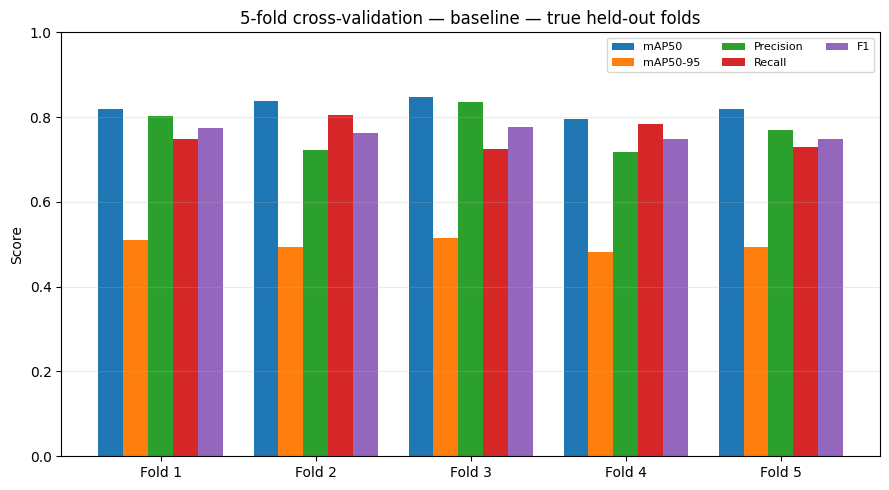

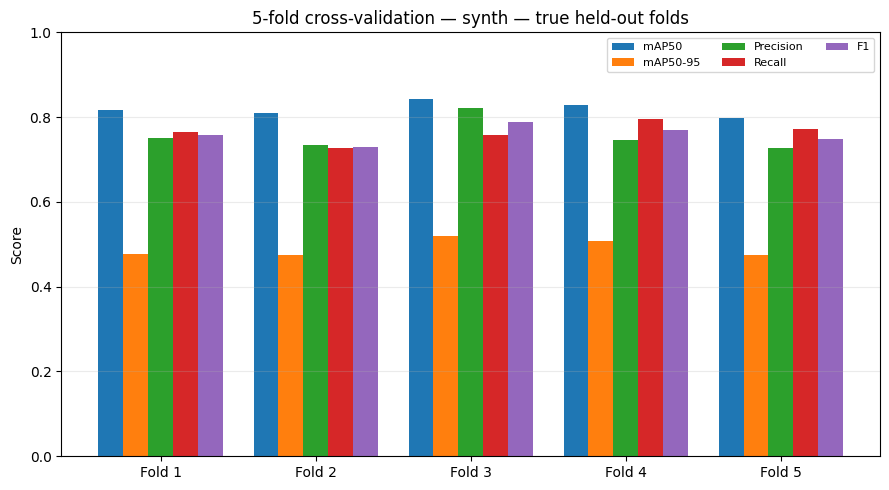

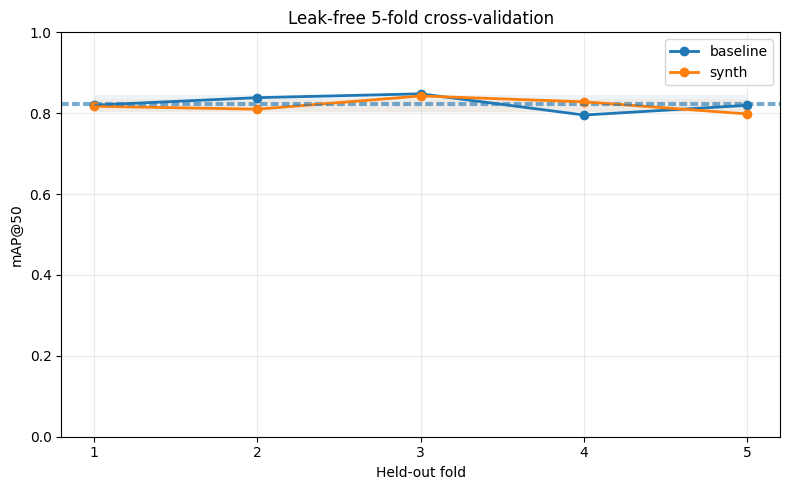


BASELINE → SYNTH PAIRED DIFFERENCES
 fold  baseline_mAP50  synth_mAP50  delta_mAP50  baseline_mAP50-95  synth_mAP50-95  delta_mAP50-95  baseline_Precision  synth_Precision  delta_Precision  baseline_Recall  synth_Recall  delta_Recall  baseline_F1  synth_F1  delta_F1
    1          0.8200       0.8172      -0.0028             0.5108          0.4768         -0.0339              0.8033           0.7502          -0.0531           0.7483        0.7658        0.0175       0.7748    0.7579   -0.0169
    2          0.8385       0.8100      -0.0285             0.4945          0.4738         -0.0207              0.7218           0.7336           0.0117           0.8056        0.7266       -0.0790       0.7614    0.7300   -0.0314
    3          0.8479       0.8426      -0.0053             0.5156          0.5196          0.0041              0.8348           0.8226          -0.0122           0.7243        0.7574        0.0331       0.7756    0.7886    0.0130
    4          0.7955       0.8282     

In [9]:
# ============================================================
# 7. AGGREGATE CV RESULTS + FIGURES
# ============================================================
# Only each model's own true held-out fold is included.
# No off-diagonal 5x5 cross-evaluation matrix is used.

SUMMARY_DIR = EXP_ROOT / "summary"
SUMMARY_DIR.mkdir(parents=True, exist_ok=True)

rows = []
for fold in range(1, N_FOLDS + 1):
    for mode in ["baseline", "synth"]:
        p = EXP_ROOT / "folds" / f"fold_{fold}" / mode / "metrics.csv"
        if p.exists():
            rows.append(pd.read_csv(p).iloc[0].to_dict())

cv_df = pd.DataFrame(rows)

if len(cv_df) == 0:
    raise RuntimeError("No completed fold metrics were found.")

cv_df = cv_df.sort_values(["mode", "fold"]).reset_index(drop=True)
cv_df.to_csv(SUMMARY_DIR / "cv_per_fold_metrics.csv", index=False)

metric_cols = ["mAP50", "mAP50-95", "Precision", "Recall", "F1"]

summary_rows = []
for mode, g in cv_df.groupby("mode"):
    for m in metric_cols:
        summary_rows.append({
            "mode": mode,
            "metric": m,
            "mean": g[m].mean(),
            "std": g[m].std(ddof=1),
            "min": g[m].min(),
            "max": g[m].max(),
            "n_folds": len(g),
        })

stats_df = pd.DataFrame(summary_rows)
stats_df.to_csv(SUMMARY_DIR / "cv_summary_stats.csv", index=False)

print("\nPER-FOLD HELD-OUT RESULTS")
print("=" * 80)
print(
    cv_df[
        ["fold", "mode", "mAP50", "mAP50-95", "Precision", "Recall", "F1"]
    ].round(4).to_string(index=False)
)

print("\nMEAN ± SD")
print("=" * 80)
for mode, g in cv_df.groupby("mode"):
    print(f"\n{mode.upper()}")
    for m in metric_cols:
        print(f"  {m:10s}: {g[m].mean():.4f} ± {g[m].std(ddof=1):.4f}")

# ------------------------------------------------------------
# Figure 1: per-fold held-out metrics
# ------------------------------------------------------------
for mode, g in cv_df.groupby("mode"):
    g = g.sort_values("fold")

    fig, ax = plt.subplots(figsize=(9, 5))
    x = np.arange(len(g))
    width = 0.16

    for i, m in enumerate(metric_cols):
        ax.bar(x + (i - 2) * width, g[m].values, width, label=m)

    ax.set_xticks(x)
    ax.set_xticklabels([f"Fold {int(f)}" for f in g["fold"]])
    ax.set_ylim(0, 1)
    ax.set_ylabel("Score")
    ax.set_title(f"5-fold cross-validation — {mode} — true held-out folds")
    ax.legend(ncol=3, fontsize=8)
    ax.grid(axis="y", alpha=0.25)

    fig.tight_layout()
    fig.savefig(
        SUMMARY_DIR / f"{mode}_per_fold_metrics.png",
        dpi=200,
        bbox_inches="tight"
    )
    plt.show()

# ------------------------------------------------------------
# Figure 2: headline mAP50 with mean ± SD
# ------------------------------------------------------------
fig, ax = plt.subplots(figsize=(8, 5))

for mode, g in cv_df.groupby("mode"):
    g = g.sort_values("fold")
    ax.plot(g["fold"], g["mAP50"], marker="o", linewidth=2, label=mode)
    mu = g["mAP50"].mean()
    sd = g["mAP50"].std(ddof=1)
    ax.axhline(mu, linestyle="--", alpha=0.6)
    ax.fill_between(
        [1, N_FOLDS],
        [mu - sd, mu - sd],
        [mu + sd, mu + sd],
        alpha=0.08
    )

ax.set_xticks(range(1, N_FOLDS + 1))
ax.set_ylim(0, 1)
ax.set_xlabel("Held-out fold")
ax.set_ylabel("mAP@50")
ax.set_title("Leak-free 5-fold cross-validation")
ax.grid(alpha=0.25)
ax.legend()

fig.tight_layout()
fig.savefig(SUMMARY_DIR / "cv_map50.png", dpi=200, bbox_inches="tight")
plt.show()

# ------------------------------------------------------------
# Optional baseline vs synth paired differences
# ------------------------------------------------------------
if set(cv_df["mode"]) >= {"baseline", "synth"}:
    base = cv_df[cv_df["mode"] == "baseline"].set_index("fold")
    synth = cv_df[cv_df["mode"] == "synth"].set_index("fold")

    common = sorted(set(base.index) & set(synth.index))
    compare_rows = []

    for fold in common:
        row = {"fold": fold}
        for m in metric_cols:
            row[f"baseline_{m}"] = base.loc[fold, m]
            row[f"synth_{m}"] = synth.loc[fold, m]
            row[f"delta_{m}"] = synth.loc[fold, m] - base.loc[fold, m]
        compare_rows.append(row)

    compare_df = pd.DataFrame(compare_rows)
    compare_df.to_csv(SUMMARY_DIR / "baseline_vs_synth.csv", index=False)

    print("\nBASELINE → SYNTH PAIRED DIFFERENCES")
    print("=" * 80)
    print(compare_df.round(4).to_string(index=False))

print("\n✅ CV summaries saved to:", SUMMARY_DIR)

## Final model for deployment / NPU conversion

The next cell creates one separate final model:

- uses only the development pool (`train/` + `valid/`) to create a fresh grouped train/validation split,
- generates synthetic images from **final-training images only**,
- trains YOLOv8n,
- evaluates **once** on the untouched original `test/` set,
- saves `final_model/best.pt` and the independent test metrics.

That final `best.pt` is the model to convert for your Q6A/NPU pipeline.

In [9]:
# ============================================================
# 8. TRAIN ONE FINAL BASELINE MODEL + INDEPENDENT TEST EVALUATION
# ============================================================
# Final training strategy selected from 5-fold CV comparison:
# ORIGINAL DATA ONLY — NO SYNTHETIC IMAGES.
#
# This model is saved separately from the previous synthetic
# final model so the old experiment is preserved.
#
# IMPORTANT:
# The independent test set is used only for final evaluation.
# Do not tune hyperparameters based on its result.

FINAL_DIR = EXP_ROOT / "final_model_baseline"
FINAL_DIR.mkdir(parents=True, exist_ok=True)

if RUN_FINAL_MODEL:

    final_metrics_path = FINAL_DIR / "independent_test_metrics.csv"
    final_best_path = FINAL_DIR / "best.pt"

    # --------------------------------------------------------
    # Reuse completed baseline final model if it already exists
    # --------------------------------------------------------
    if (
        RESUME_COMPLETED
        and not FORCE_RETRAIN
        and final_metrics_path.exists()
        and final_best_path.exists()
    ):
        print("✅ Final BASELINE model already complete; reusing:")
        print(
            pd.read_csv(final_metrics_path)
            .round(4)
            .to_string(index=False)
        )

    else:

        # ----------------------------------------------------
        # 1. DEVELOPMENT POOL + UNTOUCHED TEST SET
        # ----------------------------------------------------
        dev_df = index_df[
            index_df["source_split"].isin(["train", "valid"])
        ].copy().reset_index(drop=True)

        independent_test_df = index_df[
            index_df["source_split"] == "test"
        ].copy().reset_index(drop=True)

        print("Development images :", len(dev_df))
        print("Independent test   :", len(independent_test_df))

        # ----------------------------------------------------
        # 2. FRESH GROUPED TRAIN / VALIDATION SPLIT
        # ----------------------------------------------------
        # Same strategy/seed used by the previous final model,
        # allowing a fair baseline-vs-synthetic comparison.

        final_splitter = StratifiedGroupKFold(
            n_splits=5,
            shuffle=True,
            random_state=SEED + 999
        )

        final_train_idx, final_val_idx = next(
            final_splitter.split(
                dev_df,
                y=dev_df["positive"],
                groups=dev_df["leak_group"]
            )
        )

        final_train_df = (
            dev_df.iloc[final_train_idx]
            .reset_index(drop=True)
        )

        final_val_df = (
            dev_df.iloc[final_val_idx]
            .reset_index(drop=True)
        )

        # ----------------------------------------------------
        # 3. LEAKAGE CHECKS
        # ----------------------------------------------------
        assert not (
            set(final_train_df["leak_group"])
            & set(final_val_df["leak_group"])
        )

        assert not (
            set(final_train_df["sha256"])
            & set(independent_test_df["sha256"])
        )

        assert not (
            set(final_val_df["sha256"])
            & set(independent_test_df["sha256"])
        )

        print("✅ Final train/validation/test leakage checks passed")

        # ----------------------------------------------------
        # 4. SAVE MANIFESTS
        # ----------------------------------------------------
        final_train_df.to_csv(
            FINAL_DIR / "final_train_manifest.csv",
            index=False
        )

        final_val_df.to_csv(
            FINAL_DIR / "final_val_manifest.csv",
            index=False
        )

        independent_test_df.to_csv(
            FINAL_DIR / "independent_test_manifest.csv",
            index=False
        )

        # ----------------------------------------------------
        # 5. CREATE LOCAL DATASET
        # ----------------------------------------------------
        local_final = LOCAL_WORK / "final_model_baseline"

        if local_final.exists():
            shutil.rmtree(local_final)

        local_final.mkdir(
            parents=True,
            exist_ok=True
        )

        dataset_dir = local_final / "dataset"

        materialize_original_partition(
            final_train_df,
            dataset_dir / "train"
        )

        materialize_original_partition(
            final_val_df,
            dataset_dir / "val"
        )

        materialize_original_partition(
            independent_test_df,
            dataset_dir / "test"
        )

        # ----------------------------------------------------
        # IMPORTANT:
        # NO SYNTHETIC GENERATION
        # NO add_synthetic_to_training()
        # ----------------------------------------------------

        train_count = len([
            p for p in (dataset_dir / "train/images").iterdir()
            if p.suffix.lower() in SUPPORTED_EXTS
        ])

        val_count = len([
            p for p in (dataset_dir / "val/images").iterdir()
            if p.suffix.lower() in SUPPORTED_EXTS
        ])

        test_count = len([
            p for p in (dataset_dir / "test/images").iterdir()
            if p.suffix.lower() in SUPPORTED_EXTS
        ])

        assert train_count == len(final_train_df)
        assert val_count == len(final_val_df)
        assert test_count == len(independent_test_df)

        # ----------------------------------------------------
        # 6. YOLO DATA YAML
        # ----------------------------------------------------
        yaml_path = local_final / "data.yaml"

        write_yolo_yaml(
            dataset_dir,
            yaml_path
        )

        print("\nFINAL BASELINE TRAINING COUNTS")
        print("=" * 55)
        print("Original train   :", train_count)
        print("Synthetic        :", 0)
        print("Validation       :", val_count)
        print("Independent test :", test_count)

        # ----------------------------------------------------
        # 7. TRAIN FINAL BASELINE MODEL
        # ----------------------------------------------------
        seed_everything(SEED + 999)

        model = YOLO(MODEL_WEIGHTS)

        train_result = model.train(
            data=str(yaml_path),
            epochs=EPOCHS,
            imgsz=IMGSZ,
            batch=BATCH_SIZE,
            device=DEVICE,
            patience=PATIENCE,
            workers=WORKERS,

            seed=SEED + 999,
            deterministic=True,

            project=str(local_final),
            name="train_run",
            exist_ok=True,

            verbose=True,
            plots=True,
        )

        # ----------------------------------------------------
        # 8. LOAD BEST CHECKPOINT
        # ----------------------------------------------------
        best_pt = (
            local_final
            / "train_run"
            / "weights"
            / "best.pt"
        )

        if not best_pt.exists():
            raise FileNotFoundError(best_pt)

        print("\n✅ Best baseline checkpoint:")
        print(best_pt)

        best_model = YOLO(str(best_pt))

        # ----------------------------------------------------
        # 9. INDEPENDENT TEST EVALUATION
        # ----------------------------------------------------
        test_result = best_model.val(
            data=str(yaml_path),
            split="test",

            imgsz=IMGSZ,
            batch=BATCH_SIZE,
            device=DEVICE,

            project=str(local_final),
            name="independent_test_eval",
            exist_ok=True,

            plots=True,
            verbose=False,
        )

        m = extract_metrics(test_result)

        # ----------------------------------------------------
        # 10. SAVE FINAL METRICS
        # ----------------------------------------------------
        final_row = {
            "training_mode": "baseline_no_synthetic",

            **m,

            "train_original_images": len(final_train_df),
            "train_synthetic_images": 0,

            "val_images": len(final_val_df),

            "independent_test_images":
                len(independent_test_df),

            "epochs_requested": EPOCHS,

            "seed": SEED + 999,
        }

        pd.DataFrame(
            [final_row]
        ).to_csv(
            local_final / "independent_test_metrics.csv",
            index=False
        )

        # ----------------------------------------------------
        # 11. COPY PERSISTENT OUTPUTS TO GOOGLE DRIVE
        # ----------------------------------------------------
        shutil.copy2(
            best_pt,
            FINAL_DIR / "best.pt"
        )

        shutil.copy2(
            yaml_path,
            FINAL_DIR / "data.yaml"
        )

        shutil.copy2(
            local_final / "independent_test_metrics.csv",
            FINAL_DIR / "independent_test_metrics.csv"
        )

        sync_tree(
            local_final / "train_run",
            FINAL_DIR / "train_run"
        )

        sync_tree(
            local_final / "independent_test_eval",
            FINAL_DIR / "independent_test_eval"
        )

        # ----------------------------------------------------
        # 12. DISPLAY RESULT
        # ----------------------------------------------------
        print("\n")
        print("=" * 70)
        print("FINAL BASELINE — INDEPENDENT TEST RESULT")
        print("=" * 70)

        for k, v in m.items():
            print(f"{k:10s}: {v:.4f}")

        print("\nTraining strategy : ORIGINAL DATA ONLY")
        print("Synthetic images  : 0")

        print("\n✅ Final baseline deployment model:")
        print(FINAL_DIR / "best.pt")

        # ----------------------------------------------------
        # CLEAN GPU MEMORY
        # ----------------------------------------------------
        del model
        del best_model
        del train_result
        del test_result

        clear_cuda()

else:
    print(
        "RUN_FINAL_MODEL=False — "
        "final baseline model step skipped."
    )

Development images : 1091
Independent test   : 42
✅ Final train/validation/test leakage checks passed

FINAL BASELINE TRAINING COUNTS
Original train   : 869
Synthetic        : 0
Validation       : 222
Independent test : 42
New https://pypi.org/project/ultralytics/8.4.174 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.173 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=30, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/ganoderma_cv_work/final_model_baseline/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=True

In [16]:
# ============================================================
# 9. OPTIONAL: EXPORT FINAL MODEL TO ONNX FOR EDGE/QNN WORK
# ============================================================
# Keep this False until the final best.pt exists.


if EXPORT_FINAL_ONNX:
    final_best = FINAL_DIR / "best.pt"
    if not final_best.exists():
        raise FileNotFoundError(final_best)

    export_model = YOLO(str(final_best))
    onnx_path = export_model.export(
        format="onnx",
        imgsz=IMGSZ,
        opset=13,
        simplify=True,
        dynamic=False,
    )

    onnx_path = Path(onnx_path)
    drive_onnx = FINAL_DIR / "final_yolov8s.onnx"
    shutil.copy2(onnx_path, drive_onnx)
    print("✅ ONNX saved:", drive_onnx)
else:
    print("EXPORT_FINAL_ONNX=False — export skipped.")

Ultralytics 8.4.173 🚀 Python-3.13.15 torch-2.11.0+cu130 CPU (Intel Xeon CPU @ 2.00GHz)
💡 ProTip: Export to OpenVINO format for best performance on Intel hardware. Learn more at https://docs.ultralytics.com/integrations/openvino
Model summary (fused): 72 layers, 3,005,843 parameters, 0 gradients, 8.1 GFLOPs

PyTorch: starting from '/content/drive/MyDrive/ganoderma/experiments/leak_free_yolov8n_cv_v1/final_model/best.pt' with input shape (1, 3, 640, 640) BCHW and output shape(s) (1, 5, 8400) (6.0 MB)
requirements: Ultralytics requirements ['onnx>=1.12.0,<2.0.0', 'onnxruntime', 'onnxslim>=0.1.82'] not found, attempting AutoUpdate...
Using Python 3.13.15 environment at: /usr
Resolved 12 packages in 315ms
Prepared 4 packages in 555ms
Installed 4 packages in 40ms
 + colorama==0.4.6
 + onnx==1.23.2
 + onnxruntime==1.30.0
 + onnxslim==0.1.97

requirements: AutoUpdate success ✅ 1.3s
WARNING ⚠️ requirements: Restart runtime or rerun command for updates to take effect


ONNX: starting export with

In [17]:
# ============================================================
# 10. FINAL OUTPUT CHECK
# ============================================================
print("Experiment output root:")
print(EXP_ROOT)

print("\nExpected persistent structure:")
print(f"""
{EXP_ROOT}/
├── experiment_config.json
├── audits/
│   ├── dataset_index.csv
│   ├── label_issues.csv
│   ├── exact_duplicate_groups.csv
│   └── near_duplicate_candidates_dev_vs_test.csv
├── splits/
│   ├── fold_1_train.csv / fold_1_val.csv / fold_1_test.csv
│   ├── ...
│   └── fold_split_summary.csv
├── folds/
│   ├── fold_1/
│   │   ├── synthetic/
│   │   │   ├── images/
│   │   │   ├── labels/
│   │   │   ├── provenance.csv
│   │   │   └── preview.png
│   │   └── synth/
│   │       ├── best.pt
│   │       ├── metrics.csv
│   │       ├── train_run/
│   │       └── heldout_eval/
│   └── ...
├── summary/
│   ├── cv_per_fold_metrics.csv
│   ├── cv_summary_stats.csv
│   └── figures...
└── final_model/
    ├── best.pt
    ├── independent_test_metrics.csv
    ├── synthetic/
    ├── train_run/
    └── independent_test_eval/
""")

print("✅ Notebook complete.")

Experiment output root:
/content/drive/MyDrive/ganoderma/experiments/leak_free_yolov8n_cv_v1

Expected persistent structure:

/content/drive/MyDrive/ganoderma/experiments/leak_free_yolov8n_cv_v1/
├── experiment_config.json
├── audits/
│   ├── dataset_index.csv
│   ├── label_issues.csv
│   ├── exact_duplicate_groups.csv
│   └── near_duplicate_candidates_dev_vs_test.csv
├── splits/
│   ├── fold_1_train.csv / fold_1_val.csv / fold_1_test.csv
│   ├── ...
│   └── fold_split_summary.csv
├── folds/
│   ├── fold_1/
│   │   ├── synthetic/
│   │   │   ├── images/
│   │   │   ├── labels/
│   │   │   ├── provenance.csv
│   │   │   └── preview.png
│   │   └── synth/
│   │       ├── best.pt
│   │       ├── metrics.csv
│   │       ├── train_run/
│   │       └── heldout_eval/
│   └── ...
├── summary/
│   ├── cv_per_fold_metrics.csv
│   ├── cv_summary_stats.csv
│   └── figures...
└── final_model/
    ├── best.pt
    ├── independent_test_metrics.csv
    ├── synthetic/
    ├── train_run/
    └── independ